## Final Project: Data Analysis

**Members:**

- Simón Sloan García Villa 
- Alejandro Tirado Ramirez 




In [1]:
## Instalamos la librería de Fast F1 

%pip install fastf1

  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 1.0 MB/s eta 0:00:00.0 kB/s eta 0:00:01:01
  Attempting uninstall: msgpack0m╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/10 [rapidfuzz]
    Found existing installation: msgpack 1.0.3━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/10 [rapidfuzz]
    Uninstalling msgpack-1.0.3:━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
      Successfully uninstalled msgpack-1.0.3╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
  Attempting uninstall: attrs╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
    Found existing installation: attrs 24.3.0━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
    Uninstalling attrs-24.3.0:╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
      Successfully uninstalled attrs-24.3.0m╺━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/10 [msgpack]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [fastf1]━━  9/10 [fastf1]core]
Note: you may need to restart the

In [3]:
import fastf1 


## Configuramos la carpeta que va a guardar el cache

fastf1.Cache.enable_cache('../CacheFastF1')



/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


## Iniciamos sesión para poder usar la API oficial 

In [6]:
%pip install python-dotenv


Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
from dotenv import dotenv_values


config = dotenv_values("../.env")

os.environ['F1_USERNAME'] = config.get('address_f1')
os.environ['F1_PASSWORD'] = config.get('password_f1')

In [8]:
""" 
Vamos a hacer una prueba con una sesión de 2024 - La primera del año, con esto podremos mirar más a fondo la estructura de los datos. 
"""



session = fastf1.get_session(2024,'Bahrain','Q') # En este caso nos estamos fijando en la Qualy 
session.load(laps=True, telemetry=True)

results = session.results

print(results[['DriverNumber','Abbreviation','TeamName','Position','Points']])

laps = session.laps



core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
tokens         INFO 	Sign-in successful.
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api        

   DriverNumber Abbreviation         TeamName  Position  Points
1             1          VER  Red Bull Racing       1.0     NaN
16           16          LEC          Ferrari       2.0     NaN
63           63          RUS         Mercedes       3.0     NaN
55           55          SAI          Ferrari       4.0     NaN
11           11          PER  Red Bull Racing       5.0     NaN
14           14          ALO     Aston Martin       6.0     NaN
4             4          NOR          McLaren       7.0     NaN
81           81          PIA          McLaren       8.0     NaN
44           44          HAM         Mercedes       9.0     NaN
27           27          HUL     Haas F1 Team      10.0     NaN
22           22          TSU               RB      11.0     NaN
18           18          STR     Aston Martin      12.0     NaN
23           23          ALB         Williams      13.0     NaN
3             3          RIC               RB      14.0     NaN
20           20          MAG     Haas F1

Excelente !! Ahora el siguiente paso, será precisamente proceder con más datos de telemetría. Así podremos darnos una pista e iniciar posteriormente con el analisis de datos descriptivo explotario. 

/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(
/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/core.py:3245: FutureWarning: pick_driver is deprecated and will be removed in a future release. Use pick_drivers instead.
  warnings.warn(("pick_driver is deprecated and will be removed"
/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/core.py:3245: FutureWarning: pick_driver is deprecated and will be removed in a future release. Use pick_drivers instead.
  warnings.warn(("pick_driver is deprecated and will be removed"


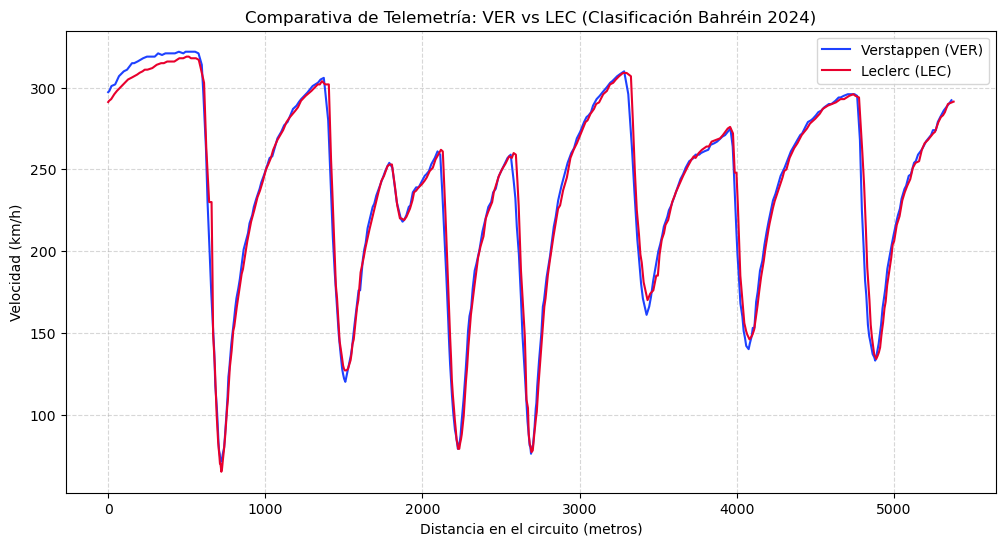

In [9]:
import matplotlib.pyplot as plt
import fastf1.plotting

# 1. Configurar el estilo visual de FastF1 para gráficos
fastf1.plotting.setup_mpl(misc_mpl_mods=False)

# 2. Seleccionar las vueltas más rápidas de Verstappen (VER) y Leclerc (LEC)
lap_ver = session.laps.pick_driver('VER').pick_fastest()
lap_lec = session.laps.pick_driver('LEC').pick_fastest()

# 3. Obtener la telemetría detallada de cada vuelta
telemetry_ver = lap_ver.get_telemetry()
telemetry_lec = lap_lec.get_telemetry()

# 4. Crear la gráfica de comparación de velocidad
fig, ax = plt.subplots(figsize=(12, 6))

# Graficar Verstappen en azul (color de Red Bull) y Leclerc en rojo (Ferrari)
ax.plot(telemetry_ver['Distance'], telemetry_ver['Speed'], label='Verstappen (VER)', color='#1e41ff')
ax.plot(telemetry_lec['Distance'], telemetry_lec['Speed'], label='Leclerc (LEC)', color='#e8002d')

# Ajustes del gráfico
ax.set_title('Comparativa de Telemetría: VER vs LEC (Clasificación Bahréin 2024)')
ax.set_xlabel('Distancia en el circuito (metros)')
ax.set_ylabel('Velocidad (km/h)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()


Como podemos ver, la grafica no es solo ascendente o descendente. Sino que más bien, tiene sus zonas donde hay frenadas fuertes y posteriormente grandes aceleraciones. Esto es precisamente lo muestran las graficas. Con unos valles muy profundos (representando zonas de frenada). 

/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(


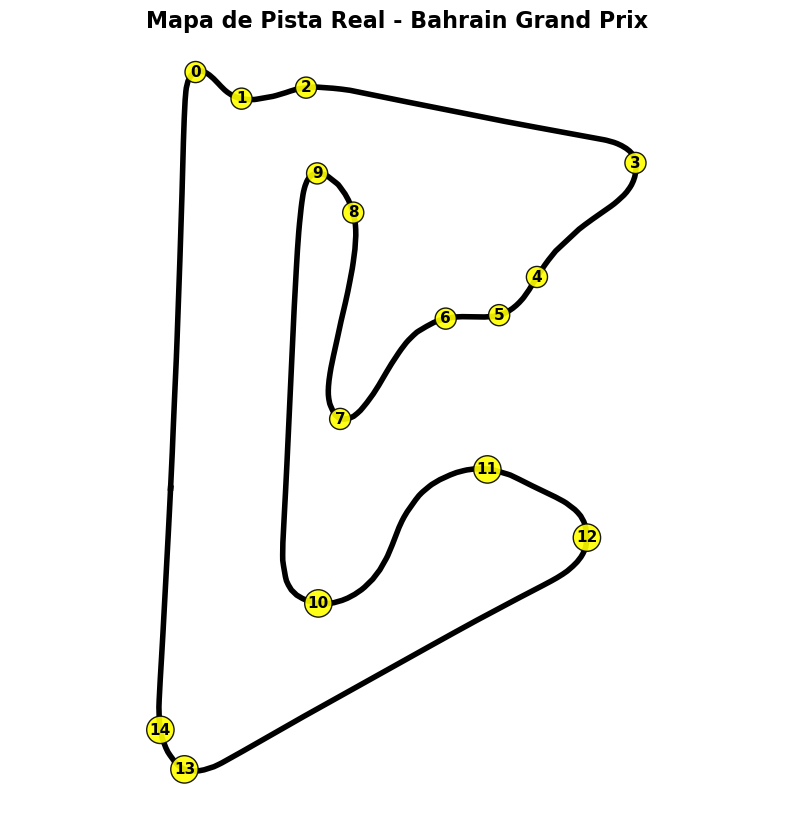

In [17]:
import matplotlib.pyplot as plt
import fastf1.plotting

# 1. Configurar estilos de FastF1
fastf1.plotting.setup_mpl(misc_mpl_mods=False)

# 2. Cargar información de curvas y la telemetría posicional de la vuelta más rápida
circuit_info = session.get_circuit_info()
fastest_lap = session.laps.pick_fastest()
telemetry = fastest_lap.get_telemetry()

# 3. LIMPIEZA CRUCIAL: Eliminamos filas donde X o Y sean NaN para evitar el lienzo vacío
telemetry_clean = telemetry.dropna(subset=['X', 'Y'])

fig, ax = plt.subplots(figsize=(10, 10))

# 4. Dibujar el trazado real y curvo de la pista (usando los datos limpios en negro)
ax.plot(telemetry_clean['X'], telemetry_clean['Y'], color='black', linewidth=4, zorder=1)

# 5. Colocar los marcadores numéricos de las curvas en sus posiciones exactas
for num, corner in circuit_info.corners.iterrows():
    txt = f"{num}"
    ax.text(corner['X'], corner['Y'], txt,
            va='center', ha='center',
            size=11, weight='bold', color='black',
            bbox=dict(boxstyle='circle,pad=0.2', fc='yellow', ec='black', alpha=0.9),
            zorder=2)

# Ajustes estéticos finales
ax.set_title(f'Mapa de Pista Real - Bahrain Grand Prix', size=16, weight='bold')
plt.axis('equal')
plt.axis('off')

plt.show()


Excelente, ahora lo que vamos a hacer es simular una vuelta donde sobrepongamos los resultados de Verstappen y de Leclerc (primero y segundo en la clasificación). 

/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/plotting/_plotting.py:56: FutureWarning: The `misc_mpl_mods` argument was dropped from `.setup_mpl()` in version 3.6.0 and has no effect anymore. It will be removed in a future version of FastF1.
  warnings.warn(
/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/core.py:3245: FutureWarning: pick_driver is deprecated and will be removed in a future release. Use pick_drivers instead.
  warnings.warn(("pick_driver is deprecated and will be removed"
/home/simonsloan/anaconda3/lib/python3.13/site-packages/fastf1/core.py:3245: FutureWarning: pick_driver is deprecated and will be removed in a future release. Use pick_drivers instead.
  warnings.warn(("pick_driver is deprecated and will be removed"


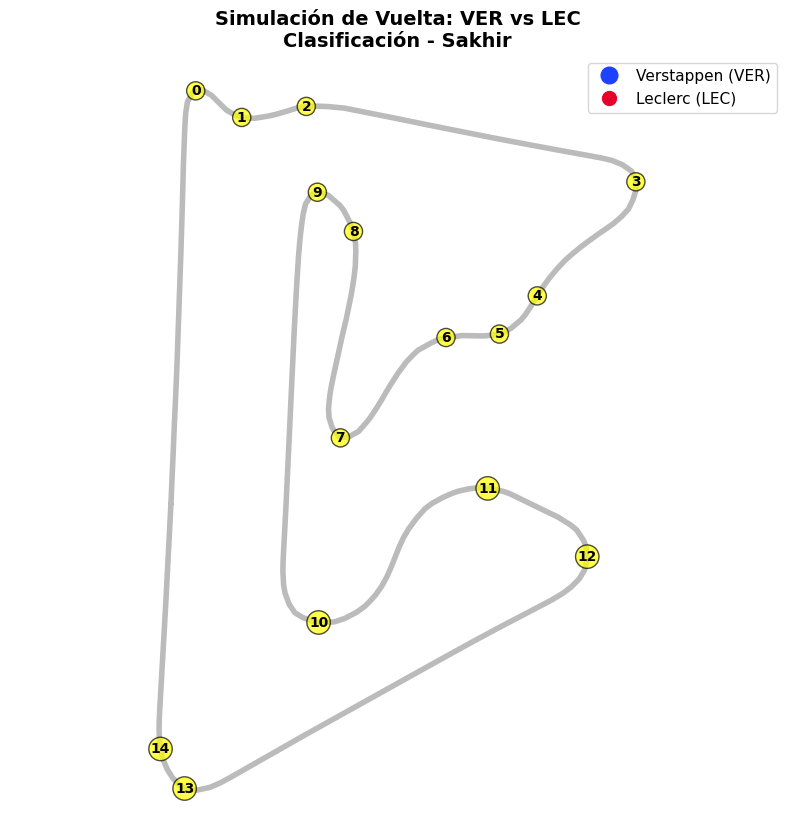

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import fastf1.plotting

# 1. Configurar estilos estéticos de FastF1
fastf1.plotting.setup_mpl(misc_mpl_mods=False)

# 2. Extraer información de curvas y las vueltas más rápidas de ambos pilotos
circuit_info = session.get_circuit_info()
lap_ver = session.laps.pick_driver('VER').pick_fastest()
lap_lec = session.laps.pick_driver('LEC').pick_fastest()

# 3. Obtener telemetrías limpiando valores nulos (NaN)
telemetry_ver = lap_ver.get_telemetry().dropna(subset=['X', 'Y', 'Distance'])
telemetry_lec = lap_lec.get_telemetry().dropna(subset=['X', 'Y', 'Distance'])

# 4. Crear un eje de distancia común para sincronizar ambos autos (desde 0 hasta el final de la vuelta)
target_distance = np.linspace(0, max(telemetry_ver['Distance'].max(), telemetry_lec['Distance'].max()), 300)

# Interpolar las coordenadas X e Y de cada piloto sobre la distancia común
x_ver = np.interp(target_distance, telemetry_ver['Distance'], telemetry_ver['X'])
y_ver = np.interp(target_distance, telemetry_ver['Distance'], telemetry_ver['Y'])

x_lec = np.interp(target_distance, telemetry_lec['Distance'], telemetry_lec['X'])
y_lec = np.interp(target_distance, telemetry_lec['Distance'], telemetry_lec['Y'])

# 5. Configurar el lienzo de la gráfica
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_title("Simulación de Vuelta: VER vs LEC\nClasificación - Sakhir", size=14, weight='bold')

# Dibujar el trazado base de la pista en gris de fondo
ax.plot(x_ver, y_ver, color='#555555', linewidth=4, alpha=0.4, zorder=1)

# Dibujar los números de las curvas
for num, corner in circuit_info.corners.iterrows():
    ax.text(corner['X'], corner['Y'], f"{num}", va='center', ha='center',
            size=10, weight='bold', color='black',
            bbox=dict(boxstyle='circle,pad=0.15', fc='yellow', ec='black', alpha=0.7), zorder=2)

# Crear los puntos móviles que representarán a los autos (Azul para Red Bull, Rojo para Ferrari)
dot_ver, = ax.plot([], [], 'o', color='#1e41ff', markersize=12, label='Verstappen (VER)', zorder=4)
dot_lec, = ax.plot([], [], 'o', color='#e8002d', markersize=10, label='Leclerc (LEC)', zorder=5)

ax.legend(loc='upper right', fontsize=11)
plt.axis('equal')
plt.axis('off')

# 6. Funciones para inicializar y actualizar la animación cuadro por cuadro
def init():
    dot_ver.set_data([], [])
    dot_lec.set_data([], [])
    return dot_ver, dot_lec

def update(frame):
    # Desplegamos la posición correspondiente al cuadro (frame) actual
    dot_ver.set_data([x_ver[frame]], [y_ver[frame]])
    dot_lec.set_data([x_lec[frame]], [y_lec[frame]])
    return dot_ver, dot_lec

# 7. Crear la animación
# 'frames=300' recorre todo el circuito, 'interval=50' controla la velocidad de reproducción
ani = FuncAnimation(fig, update, frames=len(target_distance), init_func=init, blit=True, interval=50)

plt.show()


In [26]:
import numpy as np
import plotly.graph_objects as go

# La sesión debe haberse cargado en la celda anterior.
circuit_info = session.get_circuit_info()
lap_ver = session.laps.pick_drivers('VER').pick_fastest()
lap_lec = session.laps.pick_drivers('LEC').pick_fastest()


def posiciones_vuelta(lap):
    """Obtiene posiciones y tiempos relativos a la salida de la vuelta."""
    if lap is None or lap['LapStartTime'] is None or lap['Time'] is None:
        raise ValueError('No se encontró una vuelta rápida con tiempos válidos.')
    # Las muestras exteriores permiten interpolar las posiciones exactas en la meta.
    pos = lap.get_pos_data(pad=1, pad_side='both').dropna(subset=['SessionTime', 'X', 'Y'])
    pos = pos.sort_values('SessionTime').drop_duplicates('SessionTime')
    tiempos = (pos['SessionTime'] - lap['LapStartTime']).dt.total_seconds().to_numpy()
    duracion = (lap['Time'] - lap['LapStartTime']).total_seconds()
    if (len(tiempos) < 2 or not np.isfinite(duracion) or duracion <= 0
            or tiempos[0] > 0 or tiempos[-1] < duracion):
        raise ValueError('La telemetría no cubre el inicio y el final de la vuelta.')
    return tiempos, pos['X'].to_numpy(), pos['Y'].to_numpy(), duracion


def interpolar(datos, tiempos):
    t, x, y, duracion = datos
    tiempos = np.clip(tiempos, 0, duracion)
    return np.interp(tiempos, t, x), np.interp(tiempos, t, y)


ver = posiciones_vuelta(lap_ver)
lec = posiciones_vuelta(lap_lec)
# Comparten el mismo reloj; cada piloto se detiene al completar su vuelta.
tiempos = np.linspace(0, max(ver[3], lec[3]), 450)
x_ver, y_ver = interpolar(ver, tiempos)
x_lec, y_lec = interpolar(lec, tiempos)

fig = go.Figure()
fig.add_trace(go.Scatter(x=x_ver, y=y_ver, mode='lines', name='Circuito',
                         line=dict(color='#888888', width=5), hoverinfo='skip'))
fig.add_trace(go.Scatter(
    x=circuit_info.corners['X'], y=circuit_info.corners['Y'], mode='markers+text',
    text=[f"{c['Number']}{c['Letter']}" for _, c in circuit_info.corners.iterrows()],
    textposition='middle center', textfont=dict(color='black', size=10),
    marker=dict(size=20, color='#ffe45c', line=dict(color='black', width=1)),
    name='Curvas', hoverinfo='text'))
fig.add_trace(go.Scatter(x=[x_ver[0]], y=[y_ver[0]], mode='markers',
                         name=f'Verstappen ({ver[3]:.3f} s)',
                         marker=dict(size=16, color='#1e41ff')))
fig.add_trace(go.Scatter(x=[x_lec[0]], y=[y_lec[0]], mode='markers',
                         name=f'Leclerc ({lec[3]:.3f} s)',
                         marker=dict(size=13, color='#e8002d')))

fig.frames = [go.Frame(
    name=str(i), traces=[2, 3],
    data=[go.Scatter(x=[x_ver[i]], y=[y_ver[i]]),
          go.Scatter(x=[x_lec[i]], y=[y_lec[i]])],
    layout=go.Layout(title_text=f'Verstappen vs Leclerc — Bahréin 2024<br>Tiempo: {t:.2f} s')
) for i, t in enumerate(tiempos)]

fig.update_layout(
    title='Verstappen vs Leclerc — Bahréin 2024<br>Tiempo: 0.00 s',
    height=750, xaxis=dict(visible=False),
    yaxis=dict(visible=False, scaleanchor='x', scaleratio=1),
    legend=dict(orientation='h', y=1.08),
    updatemenus=[dict(type='buttons', showactive=False, x=0, y=-0.05, buttons=[
        dict(label='▶ Reproducir', method='animate',
             args=[None, dict(frame=dict(duration=50, redraw=False),
                              transition=dict(duration=0), fromcurrent=True)]),
        dict(label='❚❚ Pausar', method='animate',
             args=[[None], dict(frame=dict(duration=0, redraw=False),
                                transition=dict(duration=0), mode='immediate')])
    ])],
    sliders=[dict(active=0, x=0.22, len=0.75, y=-0.05,
                  currentvalue=dict(prefix='Cuadro: '),
                  steps=[dict(label='', method='animate',
                              args=[[str(i)], dict(mode='immediate',
                                    frame=dict(duration=0, redraw=False),
                                    transition=dict(duration=0))])
                         for i in range(len(tiempos))])]
)
fig.show()


Ya tenemos una animación con datos reales corriendo. Ahora, nuestro proposito será mirar que datos tenemos. Y con eso, determinar cuales son útiles, en que estado vienen, y si es conveniente realizar limpieza de los mismos.

In [27]:
print(session.results.columns)

Index(['DriverNumber', 'BroadcastName', 'Abbreviation', 'DriverId', 'TeamName',
       'TeamColor', 'TeamId', 'FirstName', 'LastName', 'FullName',
       'HeadshotUrl', 'CountryCode', 'Position', 'ClassifiedPosition',
       'GridPosition', 'Q1', 'Q2', 'Q3', 'Time', 'Status', 'Points', 'Laps'],
      dtype='object')


Esto lo que nos proporciona, son los datos finales, después de una sesión. Sin embargo, estos datos por sí solos, no nos ayudan a hacer ningúna predicción. Tenemos que pasar ahora a una sesión de una carrera, para ahora sí, poder hacer la comparativa con los datos que si tienen un poco más de utilidad (como por ejemplo, en que vuelta suele parar). Esa será nuestra tarea en el momento. 


In [32]:
# 1. Seleccionar la vuelta más rápida de la sesión
vuelta_rapida = session.laps.pick_fastest()

# 2. Obtener la telemetría unificada de la vuelta
telemetria = vuelta_rapida.get_telemetry()

# 3. Mostrar las primeras filas usando la columna correcta ('nGear')
print(f"--- Telemetría de la vuelta rápida de {vuelta_rapida['Driver']} ---")
print(telemetria[['SessionTime', 'Speed', 'RPM', 'nGear', 'Throttle', 'Brake']].head(10))


--- Telemetría de la vuelta rápida de LEC ---
              SessionTime       Speed           RPM  nGear  Throttle  Brake
2  0 days 00:52:03.177000  291.196428  11713.732130      7      99.0  False
3  0 days 00:52:03.202000  291.464287  11718.821455      7      99.0  False
4  0 days 00:52:03.252000  292.000000  11729.000000      7      99.0  False
5  0 days 00:52:03.402000  292.937501  10810.249216      7      99.0  False
6  0 days 00:52:03.412000  293.000000  10749.000000      7      99.0  False
7  0 days 00:52:03.562000  294.875002  10565.874844      7      99.0  False
8  0 days 00:52:03.652000  296.000000  10456.000000      8      99.0  False
9  0 days 00:52:03.852000  298.000000  10544.000000      8      99.0  False
10 0 days 00:52:03.922000  298.583334  10591.541754      8      99.0  False
11 0 days 00:52:04.092000  300.000000  10707.000000      8      99.0  False


Ya vemos una aproximación a los datos que necesitamos, tenemos una ubicación temporar en el tiempo, para la vulta de Leclerc por ejemplo, tenemos por fracción de segundo, a que velocidad iba, revoluciones por minuto, marcha, y si es que estaba frenando. Esto es especialmente útil, porque cuando se frena de forma agresiva es cuando más se desgastan los neumaticos, debido a las fuerzas G que tiran el carro hacía afuera. A continuación una imagen para ilustrar la situación: 

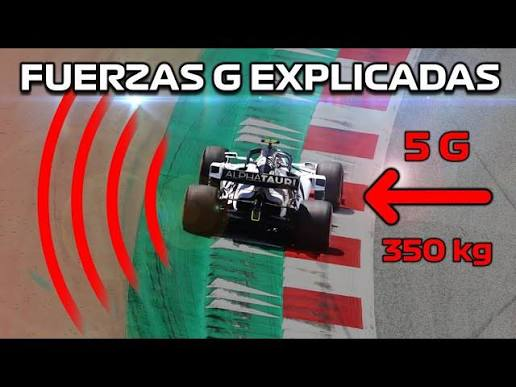

## Análisis de una sesión de carrera

Cargamos la carrera de Bahréin de 2024 por separado de la clasificación. Esto ya que las vueltas de carrera permiten explorar la estrategia de neumáticos y las entradas a boxes.


In [33]:
# Cambia estos valores para analizar otra carrera.
anio_carrera = 2024
gran_premio = 'Bahrain'
session_carrera = fastf1.get_session(anio_carrera, gran_premio, 'R')
session_carrera.load(laps=True, telemetry=True)
vueltas_carrera = session_carrera.laps

print(f'Carrera: {gran_premio} {anio_carrera}')
print(f'Vueltas registradas: {len(vueltas_carrera)}')
display(session_carrera.results[['Abbreviation', 'TeamName', 'Position']].head(10))


core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No ca

Carrera: Bahrain 2024
Vueltas registradas: 1129


,Abbreviation,TeamName,Position
1,VER,Red Bull Racing,1.0
11,PER,Red Bull Racing,2.0
55,SAI,Ferrari,3.0
16,LEC,Ferrari,4.0
63,RUS,Mercedes,5.0
4,NOR,McLaren,6.0
44,HAM,Mercedes,7.0
81,PIA,McLaren,8.0
14,ALO,Aston Martin,9.0
18,STR,Aston Martin,10.0


### Vueltas y paradas en boxes

Una vuelta con `PitInTime` registra una entrada a boxes; `PitOutTime` indica la salida. Los tiempos corresponden al reloj de la sesión, no a la duración de la parada.


In [34]:
# Ejemplo: información de las vueltas de Leclerc en carrera.
piloto = 'LEC'
vueltas_piloto = vueltas_carrera.pick_drivers(piloto)
columnas = ['LapNumber', 'LapTime', 'Compound', 'TyreLife', 'Stint',
            'PitInTime', 'PitOutTime']
display(vueltas_piloto[columnas].head(10))

# Cada fila corresponde a una vuelta de entrada a boxes, no a una vuelta de salida.
paradas = vueltas_carrera.loc[vueltas_carrera['PitInTime'].notna(),
    ['Driver', 'LapNumber', 'PitInTime', 'Compound', 'TyreLife', 'Stint']]
print(f'Entradas a boxes registradas: {len(paradas)}')
display(paradas.sort_values(['Driver', 'LapNumber']).reset_index(drop=True))


,LapNumber,LapTime,Compound,TyreLife,Stint,PitInTime,PitOutTime
171,1.0,0 days 00:01:38.271000,SOFT,4.0,1.0,NaT,NaT
172,2.0,0 days 00:01:36.862000,SOFT,5.0,1.0,NaT,NaT
173,3.0,0 days 00:01:38.062000,SOFT,6.0,1.0,NaT,NaT
174,4.0,0 days 00:01:37.752000,SOFT,7.0,1.0,NaT,NaT
175,5.0,0 days 00:01:38.131000,SOFT,8.0,1.0,NaT,NaT
176,6.0,0 days 00:01:37.782000,SOFT,9.0,1.0,NaT,NaT
177,7.0,0 days 00:01:38.957000,SOFT,10.0,1.0,NaT,NaT
178,8.0,0 days 00:01:38.136000,SOFT,11.0,1.0,NaT,NaT
179,9.0,0 days 00:01:37.844000,SOFT,12.0,1.0,NaT,NaT
180,10.0,0 days 00:01:37.884000,SOFT,13.0,1.0,NaT,NaT


Entradas a boxes registradas: 43


,Driver,LapNumber,PitInTime,Compound,TyreLife,Stint
0,ALB,15.0,0 days 01:24:47.139000,SOFT,15.0,1.0
1,ALB,36.0,0 days 01:59:27.973000,HARD,21.0,2.0
2,ALO,15.0,0 days 01:24:42.030000,SOFT,18.0,1.0
3,ALO,41.0,0 days 02:07:16.321000,HARD,26.0,2.0
4,BOT,12.0,0 days 01:20:00.495000,SOFT,12.0,1.0
5,BOT,30.0,0 days 01:49:50.207000,HARD,18.0,2.0
6,GAS,12.0,0 days 01:19:56.823000,SOFT,12.0,1.0
7,GAS,31.0,0 days 01:51:29.011000,HARD,19.0,2.0
8,GAS,43.0,0 days 02:11:13.617000,HARD,12.0,3.0
9,HAM,12.0,0 days 01:19:44.838000,SOFT,15.0,1.0


### Telemetría de una vuelta de carrera

Como ejemplo, seleccionamos la vuelta más rápida del piloto. Puede sustituirse por un número de vuelta específico según el análisis que quieras hacer.


In [35]:
vuelta_carrera = vueltas_piloto.pick_fastest()
if vuelta_carrera is None:
    raise ValueError(f'No hay una vuelta rápida válida para {piloto} en esta carrera.')

telemetria_carrera = vuelta_carrera.get_telemetry()
print(f"Piloto: {piloto} | Vuelta: {int(vuelta_carrera['LapNumber'])} | "
      f"Tiempo: {vuelta_carrera['LapTime']}")
display(telemetria_carrera[['SessionTime', 'Speed', 'RPM', 'nGear',
                             'Throttle', 'Brake']].head(10))


Piloto: LEC | Vuelta: 36 | Tiempo: 0 days 00:01:34.090000


,SessionTime,Speed,RPM,nGear,Throttle,Brake
2,0 days 01:57:29.729000,294.000000,11152.000000,7,99.0,False
3,0 days 01:57:29.969000,296.000000,10618.000000,8,99.0,False
4,0 days 01:57:30.088000,297.785001,10656.080020,8,99.0,False
5,0 days 01:57:30.169000,299.000000,10682.000000,8,99.0,False
6,0 days 01:57:30.308000,300.737501,10693.293755,8,99.0,False
7,0 days 01:57:30.329000,301.000000,10695.000000,8,99.0,False
8,0 days 01:57:30.489000,302.000000,10741.000000,8,99.0,False
9,0 days 01:57:30.568000,302.846429,10784.732178,8,99.0,False
10,0 days 01:57:30.728000,304.560715,10873.303607,8,99.0,False
11,0 days 01:57:30.769000,305.000000,10896.000000,8,99.0,False


### Ejemplo de una entrada a boxes

Buscamos la primera entrada registrada de Leclerc y mostramos la vuelta de entrada y la primera salida posterior. La diferencia entre ambos tiempos corresponde al recorrido por el pit lane, no solo al tiempo detenido.


In [36]:
# Usa la sesión de carrera cargada en la sección anterior.
piloto_ejemplo = 'LEC'
vueltas_ejemplo = session_carrera.laps.pick_drivers(piloto_ejemplo)
entradas = vueltas_ejemplo.loc[vueltas_ejemplo['PitInTime'].notna()].sort_values('PitInTime')

if entradas.empty:
    print(f'No hay entradas a boxes registradas para {piloto_ejemplo}.')
else:
    entrada = entradas.iloc[0]
    salidas = vueltas_ejemplo.loc[
        vueltas_ejemplo['PitOutTime'].notna()
        & (vueltas_ejemplo['PitOutTime'] > entrada['PitInTime'])
    ].sort_values('PitOutTime')

    print(f"{piloto_ejemplo}: entrada en la vuelta {int(entrada['LapNumber'])} "
          f"(reloj de sesión: {entrada['PitInTime']})")
    filas = vueltas_ejemplo.loc[[entrada.name]]
    if salidas.empty:
        print('No hay una salida posterior registrada en los datos.')
    else:
        salida = salidas.iloc[0]
        duracion = (salida['PitOutTime'] - entrada['PitInTime']).total_seconds()
        print(f"Salida en la vuelta {int(salida['LapNumber'])} "
              f"(reloj de sesión: {salida['PitOutTime']})")
        print(f'Tiempo entre entrada y salida del pit lane: {duracion:.2f} s')
        filas = vueltas_ejemplo.loc[[entrada.name, salida.name]].drop_duplicates()

    display(filas[['Driver', 'LapNumber', 'PitInTime', 'PitOutTime',
                   'Compound', 'TyreLife', 'Stint']])


LEC: entrada en la vuelta 11 (reloj de sesión: 0 days 01:17:59.892000)
Salida en la vuelta 12 (reloj de sesión: 0 days 01:18:23.940000)
Tiempo entre entrada y salida del pit lane: 24.05 s


,Driver,LapNumber,PitInTime,PitOutTime,Compound,TyreLife,Stint
181,LEC,11.0,0 days 01:17:59.892000,NaT,SOFT,14.0,1.0
182,LEC,12.0,NaT,0 days 01:18:23.940000,HARD,1.0,2.0


### Inventario de datos de la sesión de carrera

Esta celda inspecciona los datos cargados por FastF1: tablas de sesión y telemetría por piloto. Muestra disponibilidad, columnas, tipos y valores faltantes; una tabla vacía no permite concluir que la fuente nunca tenga esos datos.


In [37]:
import pandas as pd
from IPython.display import display

# La sesión se carga en la sección «Análisis de una sesión de carrera».
sesion_explorar = session_carrera
conjuntos = {
    'Vueltas': 'laps',
    'Resultados': 'results',
    'Clima': 'weather_data',
    'Estado de pista': 'track_status',
    'Estado de sesión': 'session_status',
    'Mensajes de dirección de carrera': 'race_control_messages',
    'Telemetría del coche por piloto': 'car_data',
    'Posiciones por piloto': 'pos_data',
}
resumen = []
tablas = {}

for nombre, atributo in conjuntos.items():
    try:
        datos = getattr(sesion_explorar, atributo)
    except Exception as error:
        resumen.append({'Datos': nombre, 'Estado': f'No disponibles: {error}',
                        'Filas': None, 'Columnas': None})
        continue

    if isinstance(datos, dict):
        # La telemetría está agrupada por número de piloto. Se inspeccionan todos.
        partes = [tabla for tabla in datos.values()
                  if isinstance(tabla, pd.DataFrame) and not tabla.empty]
        if partes:
            datos = pd.concat(partes, ignore_index=True)
        else:
            datos = pd.DataFrame()
    if isinstance(datos, pd.DataFrame):
        tablas[nombre] = datos
        resumen.append({'Datos': nombre, 'Estado': 'Disponible' if not datos.empty else 'Vacío',
                        'Filas': len(datos), 'Columnas': len(datos.columns)})
    else:
        resumen.append({'Datos': nombre, 'Estado': 'Vacío' if datos is None else 'Disponible',
                        'Filas': None, 'Columnas': None})

print('Disponibilidad de los conjuntos de datos')
display(pd.DataFrame(resumen))
print('Información general de la sesión')
display(pd.Series(sesion_explorar.session_info, name='Valor').to_frame())

for nombre, tabla in tablas.items():
    print(f'\n{nombre}: columnas y valores faltantes')
    detalle = pd.DataFrame({
        'Tipo': tabla.dtypes.astype(str),
        'No nulos': tabla.notna().sum(),
        'Faltantes': tabla.isna().sum(),
        'Faltantes (%)': (tabla.isna().mean() * 100).round(2),
    })
    display(detalle)
    print('Ejemplo de filas:')
    display(tabla.head(3))


Disponibilidad de los conjuntos de datos


,Datos,Estado,Filas,Columnas
0,Vueltas,Disponible,1129,31
1,Resultados,Disponible,20,22
2,Clima,Disponible,157,8
3,Estado de pista,Disponible,7,3
4,Estado de sesión,Disponible,5,2
5,Mensajes de dirección de carrera,Disponible,69,9
6,Telemetría del coche por piloto,Disponible,696380,10
7,Posiciones por piloto,Disponible,719880,8


Información general de la sesión


,Valor
Meeting,"{'Key': 1229, 'Name': 'Bahrain Grand Prix', 'O..."
ArchiveStatus,{'Status': 'Generating'}
Key,9472
Type,Race
Name,Race
StartDate,2024-03-02 18:00:00
EndDate,2024-03-02 20:00:00
GmtOffset,3:00:00
Path,2024/2024-03-02_Bahrain_Grand_Prix/2024-03-02_...



Vueltas: columnas y valores faltantes


,Tipo,No nulos,Faltantes,Faltantes (%)
Time,timedelta64[ns],1129,0,0.00
Driver,object,1129,0,0.00
DriverNumber,object,1129,0,0.00
LapTime,timedelta64[ns],1128,1,0.09
LapNumber,float64,1129,0,0.00
Stint,float64,1129,0,0.00
PitOutTime,timedelta64[ns],43,1086,96.19
PitInTime,timedelta64[ns],43,1086,96.19
Sector1Time,timedelta64[ns],1108,21,1.86
Sector2Time,timedelta64[ns],1129,0,0.00


... (26 outputs left out)


Posiciones por piloto: columnas y valores faltantes


,Tipo,No nulos,Faltantes,Faltantes (%)
Date,datetime64[ns],719880,0,0.0
Status,object,719880,0,0.0
X,float64,719880,0,0.0
Y,float64,719880,0,0.0
Z,float64,719880,0,0.0
Source,object,719880,0,0.0
Time,timedelta64[ns],719880,0,0.0
SessionTime,timedelta64[ns],719880,0,0.0


Ejemplo de filas:


,Date,Status,X,Y,Z,Source,Time,SessionTime
0,2024-03-02 14:03:43.899,OnTrack,0.0,0.0,0.0,pos,0 days 00:00:01.468000,0 days 00:00:01.468000
1,2024-03-02 14:03:44.219,OnTrack,0.0,0.0,0.0,pos,0 days 00:00:01.788000,0 days 00:00:01.788000
2,2024-03-02 14:03:44.460,OnTrack,0.0,0.0,0.0,pos,0 days 00:00:02.029000,0 days 00:00:02.029000


Como podemos ver, hay datos que son fijos y otros que si dependen del momento particular de la carrera, es por esto, que teniendo en cuenta las caracteristicas del dataset, nos propondremos, solo en la RNN meter los datos que varían con el tiempo, tales como el compuesto que lleva, o el tiempo por sectores. Por su parte, temas que si son fijos (como lo es el caso del nombre de la pista o el país), lo dejaremos en otro modelo como una FNN, con el fin de explotar lo mejor de ambos enfoques. 

### Calidad de la tabla de vueltas

Revisamos valores faltantes, duplicados y eventos de boxes; después generamos un informe visual. Los tiempos se convierten a segundos únicamente en una copia para el informe.


In [38]:
import pandas as pd
from IPython.display import display

# Se utiliza una copia: la revisión no modifica los datos originales de FastF1.
datos_vueltas = pd.DataFrame(vueltas_carrera).copy()
print(f'Vueltas: {len(datos_vueltas)} | Columnas: {len(datos_vueltas.columns)}')
calidad = pd.DataFrame({
    'Tipo': datos_vueltas.dtypes.astype(str),
    'No nulos': datos_vueltas.notna().sum(),
    'Faltantes': datos_vueltas.isna().sum(),
    'Faltantes (%)': (datos_vueltas.isna().mean() * 100).round(2),
    'Valores distintos': datos_vueltas.nunique(dropna=True),
}).sort_values('Faltantes (%)', ascending=False)
display(calidad)

claves = ['Driver', 'LapNumber']
print(f"Filas completamente duplicadas: {datos_vueltas.duplicated().sum()}")
print(f"Claves piloto-vuelta repetidas: {datos_vueltas.duplicated(subset=claves, keep=False).sum()} filas")
print(f"Vueltas sin tiempo registrado: {datos_vueltas['LapTime'].isna().sum()}")
print(f"Entradas a boxes registradas: {datos_vueltas['PitInTime'].notna().sum()}")
print(f"Salidas de boxes registradas: {datos_vueltas['PitOutTime'].notna().sum()}")
print('Los valores vacíos de PitInTime y PitOutTime son esperados en vueltas sin esos eventos.')

# Convierte las duraciones a segundos para el informe, sin alterar el DataFrame original.
datos_perfil = datos_vueltas.copy()
for columna in datos_perfil.select_dtypes(include=['timedelta']).columns:
    datos_perfil[columna] = datos_perfil[columna].dt.total_seconds()

from ydata_profiling import ProfileReport
reporte_vueltas = ProfileReport(datos_perfil, title='Calidad de datos: vueltas de carrera', minimal=True)
reporte_vueltas.to_notebook_iframe()


Vueltas: 1129 | Columnas: 31


,Tipo,No nulos,Faltantes,Faltantes (%),Valores distintos
PitOutTime,timedelta64[ns],43,1086,96.19,43
PitInTime,timedelta64[ns],43,1086,96.19,43
SpeedFL,float64,1086,43,3.81,25
Sector1SessionTime,timedelta64[ns],1107,22,1.95,1107
Sector1Time,timedelta64[ns],1108,21,1.86,756
LapTime,timedelta64[ns],1128,1,0.09,1012
DriverNumber,object,1129,0,0.00,20
Stint,float64,1129,0,0.00,4
LapNumber,float64,1129,0,0.00,57
Driver,object,1129,0,0.00,20


Filas completamente duplicadas: 0
Claves piloto-vuelta repetidas: 0 filas
Vueltas sin tiempo registrado: 1
Entradas a boxes registradas: 43
Salidas de boxes registradas: 43
Los valores vacíos de PitInTime y PitOutTime son esperados en vueltas sin esos eventos.


/tmp/ipykernel_10985/318326336.py:29: DeprecationWarning:


    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    



Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 31/31 [00:00<00:00, 83831.99it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Gracias a este análisis exploratorio, podemos ver cómo los datos aparentan tener una buena calidad, aunque todavía debemos revisar algunos casos. Tenemos 11 alertas (que aisladamente podrían ser preocupantes), pero algunas tienen sentido teniendo en cuenta las características de una carrera de F1. Por ejemplo, los pilotos no paran todas las vueltas en boxes, de ahí que haya tantos valores faltantes en las columnas de entrada y salida.

Con la variable `Deleted`, debemos tener cuidado: no es como que a los pilotos les borren todas las vueltas; esto puede pasar, por ejemplo, si se salen de los límites de pista. Sin embargo, un valor faltante no necesariamente quiere decir que la vuelta no fue borrada, también puede significar que el dato no está disponible.

Por su parte, `SpeedFL` puede tener valores faltantes cuando un piloto entra a boxes o hay una bandera roja. A veces los pilotos tampoco terminan las carreras, ya sea por problemas de fiabilidad o por daños en el monoplaza, pero no podemos asumir que esa sea la razón de cada valor faltante.

Lo que sí es que debemos revisar estas alertas y valores para saber cómo los tratamos, porque esto al final puede afectar incluso la ejecución y los resultados del modelo.
